# 02 · Repurchase propensity (churn)

**Business question:** which customers are most likely **not** to buy again in the next 90 days, and how much is it worth acting on them (reactivation coupon, WhatsApp, e-mail)?

**Definition:** at cutoff date *T*, a customer with at least one paid purchase up to *T*. Label = **bought again in (T, T+90 days]**. Churn = did not buy.

**Time-based validation:** the model is trained with the Jan 15, 2026 cutoff (label up to Apr 15) and evaluated with the Jul 15, 2026 cutoff (label up to Oct 13, the end of the data). That way no future data enters training.

In [1]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.express as px
import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve
from utils_nb import sql, configurar_graficos, brl, CORES, COR_REAL, COR_PREVISTO, COR_DESTAQUE

configurar_graficos()

## Orders and identified sessions

Customers unified by CPF (duplicate accounts of the same person count as one). Test orders are left out.

In [2]:
ped = sql("""
SELECT p.pedido_id, IF(c.cpf IS NULL, c.cliente_id, MIN(c.cliente_id) OVER (PARTITION BY c.cpf)) AS cliente,
       c.tipo_cliente, c.tipo_pessoa, c.aceita_email_marketing, c.aceita_whatsapp,
       p.criado_em, p.total, p.desconto, p.frete, p.cupom_id IS NOT NULL AS usou_cupom, p.canal_venda,
       (SELECT COUNT(*) FROM devolucoes d WHERE d.pedido_id = p.pedido_id) AS devolucoes,
       (SELECT AVG(nota) FROM avaliacoes a WHERE a.pedido_id = p.pedido_id) AS nota,
       f.entregue_em, f.postado_em, f.prazo_estimado_dias
FROM pedidos p
JOIN clientes c ON c.cliente_id = p.cliente_id
LEFT JOIN fretes f ON f.pedido_id = p.pedido_id
WHERE p.pedido_teste = 0 AND p.status IN ('pago','enviado','entregue','devolvido')""")
ped["criado_em"] = pd.to_datetime(ped["criado_em"])
ped["atraso"] = ((pd.to_datetime(ped.entregue_em) - pd.to_datetime(ped.postado_em)).dt.days > ped.prazo_estimado_dias + 1).astype(float)

itens = sql("""
SELECT i.pedido_id, fam.nome AS familia, v.formato_venda, i.quantidade * v.metros_por_unidade AS metros
FROM itens_pedido i
JOIN variantes v ON v.variante_id = i.variante_id
JOIN produtos pr ON pr.produto_id = v.produto_id
JOIN categorias cat ON cat.categoria_id = pr.categoria_id
JOIN categorias fam ON fam.categoria_id = cat.categoria_pai_id""")
sess = sql("""
SELECT cliente_id AS cliente, DATE(iniciada_em) AS dia, COUNT(*) AS sessoes
FROM sessoes WHERE cliente_id IS NOT NULL GROUP BY 1, 2""")
sess["dia"] = pd.to_datetime(sess["dia"])
print(f"{ped.cliente.nunique():,} clientes, {len(ped):,} pedidos pagos, {sess.sessoes.sum():,} sessões identificadas")

47,093 clientes, 133,649 pedidos pagos, 575,808 sessões identificadas


## Features at the cutoff date

Everything is computed only with what was known up to *T*: recency, frequency, monetary value, purchase rhythm (average interval and how "late" the customer is relative to their own rhythm), fabric mix, coupon use, delivery experience and recent browsing on the website.

In [3]:
FAMILIAS = sorted(itens.familia.unique())

def montar(T, janela=90):
    T = pd.Timestamp(T)
    h = ped[ped.criado_em <= T]
    fut = ped[(ped.criado_em > T) & (ped.criado_em <= T + pd.Timedelta(days=janela))]
    g = h.sort_values("criado_em").groupby("cliente")
    X = pd.DataFrame({
        "recencia_dias": (T - g.criado_em.max()).dt.days,
        "antiguidade_dias": (T - g.criado_em.min()).dt.days,
        "pedidos": g.size(),
        "receita": g.total.sum(),
        "ticket_medio": g.total.mean(),
        "ultimo_ticket": g.total.last(),
        "pct_com_cupom": g.usou_cupom.mean(),
        "pct_frete_pago": g.frete.apply(lambda s: (s > 0).mean()),
        "devolucoes": g.devolucoes.sum(),
        "nota_media": g.nota.mean(),
        "pct_entrega_atrasada": g.atraso.mean(),
        "pct_whatsapp": g.canal_venda.apply(lambda s: (s == "whatsapp").mean()),
    })
    inter = g.criado_em.apply(lambda s: s.diff().dt.days.mean())
    X["intervalo_medio"] = inter
    X["atraso_vs_ritmo"] = X["recencia_dias"] / X["intervalo_medio"].where(X["intervalo_medio"] > 0)  # 2 pedidos no mesmo dia: intervalo 0
    X["pedidos_90d"] = h[h.criado_em > T - pd.Timedelta(days=90)].groupby("cliente").size().reindex(X.index).fillna(0)
    # mix de tecidos e rolo
    it = itens.merge(h[["pedido_id", "cliente"]], on="pedido_id")
    mix = it.pivot_table(index="cliente", columns="familia", values="metros", aggfunc="sum", fill_value=0)
    mix = mix.div(mix.sum(1), axis=0).reindex(columns=FAMILIAS, fill_value=0).add_prefix("mix_")
    X = X.join(mix)
    X["metros_por_pedido"] = it.groupby("cliente").metros.sum() / X["pedidos"]
    X["comprou_rolo"] = it.groupby("cliente").formato_venda.apply(lambda s: (s == "rolo").any()).reindex(X.index).fillna(False).astype(int)
    # navegação recente (sessões identificadas)
    s = sess[sess.dia <= T]
    X["sessoes_30d"] = s[s.dia > T - pd.Timedelta(days=30)].groupby("cliente").sessoes.sum().reindex(X.index).fillna(0)
    X["sessoes_90d"] = s[s.dia > T - pd.Timedelta(days=90)].groupby("cliente").sessoes.sum().reindex(X.index).fillna(0)
    # cadastro
    cad = ped.drop_duplicates("cliente").set_index("cliente")
    X = X.join(cad[["tipo_cliente", "tipo_pessoa", "aceita_email_marketing", "aceita_whatsapp"]])
    for t in ["hobby", "costureira", "atelie", "confeccao"]:
        X[f"tipo_{t}"] = (X.tipo_cliente == t).astype(int)
    X["pj"] = (X.tipo_pessoa == "PJ").astype(int)
    X = X.drop(columns=["tipo_cliente", "tipo_pessoa"])
    y = X.index.isin(fut.cliente.unique()).astype(int)
    receita_fut = fut.groupby("cliente").total.sum().reindex(X.index).fillna(0)
    return X, pd.Series(y, index=X.index, name="recomprou"), receita_fut

X_tr, y_tr, _ = montar("2026-01-15")
X_te, y_te, rec_te = montar("2026-07-15")
print(f"Treino: {len(X_tr):,} clientes, recompra {y_tr.mean():.1%} | Teste: {len(X_te):,} clientes, recompra {y_te.mean():.1%}")

/tmp/ipykernel_3347266/1436326694.py:29: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  mix = mix.div(mix.sum(1), axis=0).reindex(columns=FAMILIAS, fill_value=0).add_prefix("mix_")


/tmp/ipykernel_3347266/1436326694.py:29: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  mix = mix.div(mix.sum(1), axis=0).reindex(columns=FAMILIAS, fill_value=0).add_prefix("mix_")


Treino: 34,649 clientes, recompra 14.9% | Teste: 43,039 clientes, recompra 13.3%


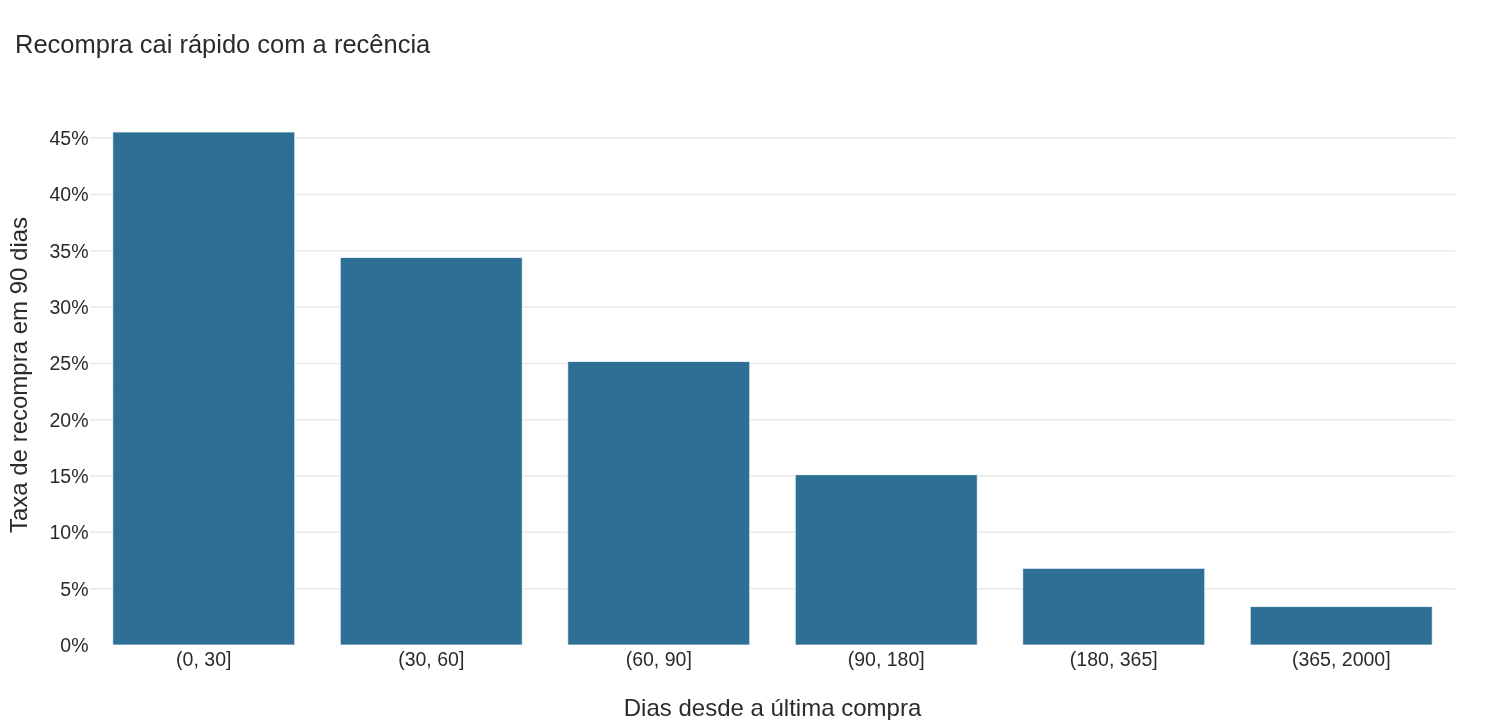

In [4]:
taxa = X_te.assign(y=y_te).groupby(pd.cut(X_te.recencia_dias, [0, 30, 60, 90, 180, 365, 2000]), observed=True).y.mean()
fig = px.bar(x=[str(i) for i in taxa.index], y=taxa.values, labels={"x": "Dias desde a última compra", "y": "Taxa de recompra em 90 dias"},
             title="Recompra cai rápido com a recência")
fig.update_traces(marker_color=COR_REAL)
fig.update_yaxes(tickformat=".0%")
fig.show()

## Models: logistic regression (reference) vs. LightGBM

In [5]:
feats = list(X_tr.columns)
X_trf, X_tef = X_tr[feats].fillna(-1), X_te[feats].fillna(-1)

logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.5))
logit.fit(X_trf, y_tr)
p_log = logit.predict_proba(X_tef)[:, 1]

params = dict(objective="binary", learning_rate=0.03, num_leaves=31, min_data_in_leaf=50, feature_fraction=0.8,
              bagging_fraction=0.8, bagging_freq=1, lambda_l2=5, verbose=-1, seed=7)
m = lgb.train(params, lgb.Dataset(X_tr[feats], y_tr), num_boost_round=500)
p_lgb = m.predict(X_te[feats])

aval = pd.DataFrame({
    nome: {"ROC AUC": roc_auc_score(y_te, p), "PR AUC": average_precision_score(y_te, p), "Brier": brier_score_loss(y_te, p)}
    for nome, p in [("Regressão logística", p_log), ("LightGBM", p_lgb)]}).T
aval.style.format("{:.3f}")

,ROC AUC,PR AUC,Brier
Regressão logística,0.828,0.492,0.089
LightGBM,0.827,0.488,0.089


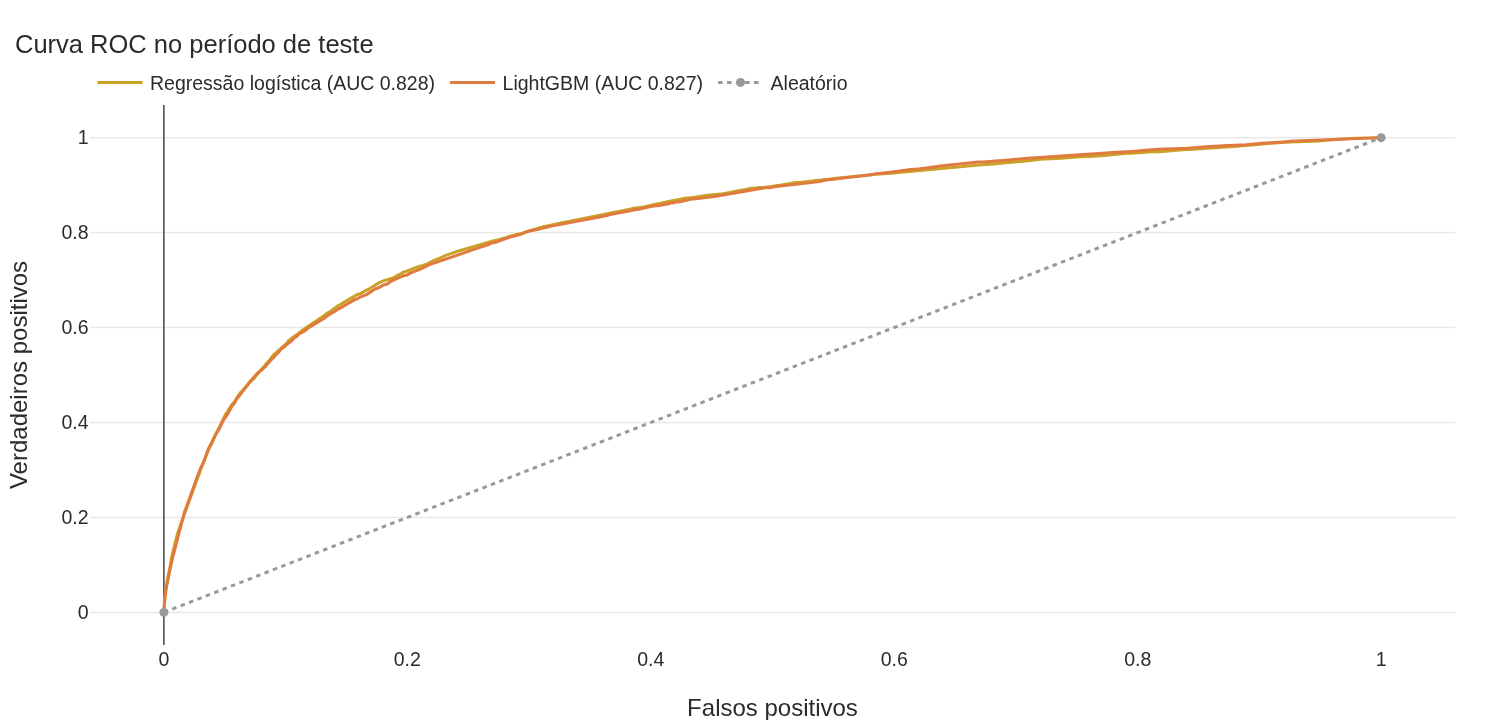

In [6]:
fig = go.Figure()
for nome, p, cor in [("Regressão logística", p_log, CORES[5]), ("LightGBM", p_lgb, COR_PREVISTO)]:
    fpr, tpr, _ = roc_curve(y_te, p)
    fig.add_scatter(x=fpr, y=tpr, name=f"{nome} (AUC {roc_auc_score(y_te, p):.3f})", line=dict(color=cor))
fig.add_scatter(x=[0, 1], y=[0, 1], name="Aleatório", line=dict(color="#999", dash="dot"))
fig.update_layout(title="Curva ROC no período de teste", xaxis_title="Falsos positivos", yaxis_title="Verdadeiros positivos")
fig.show()

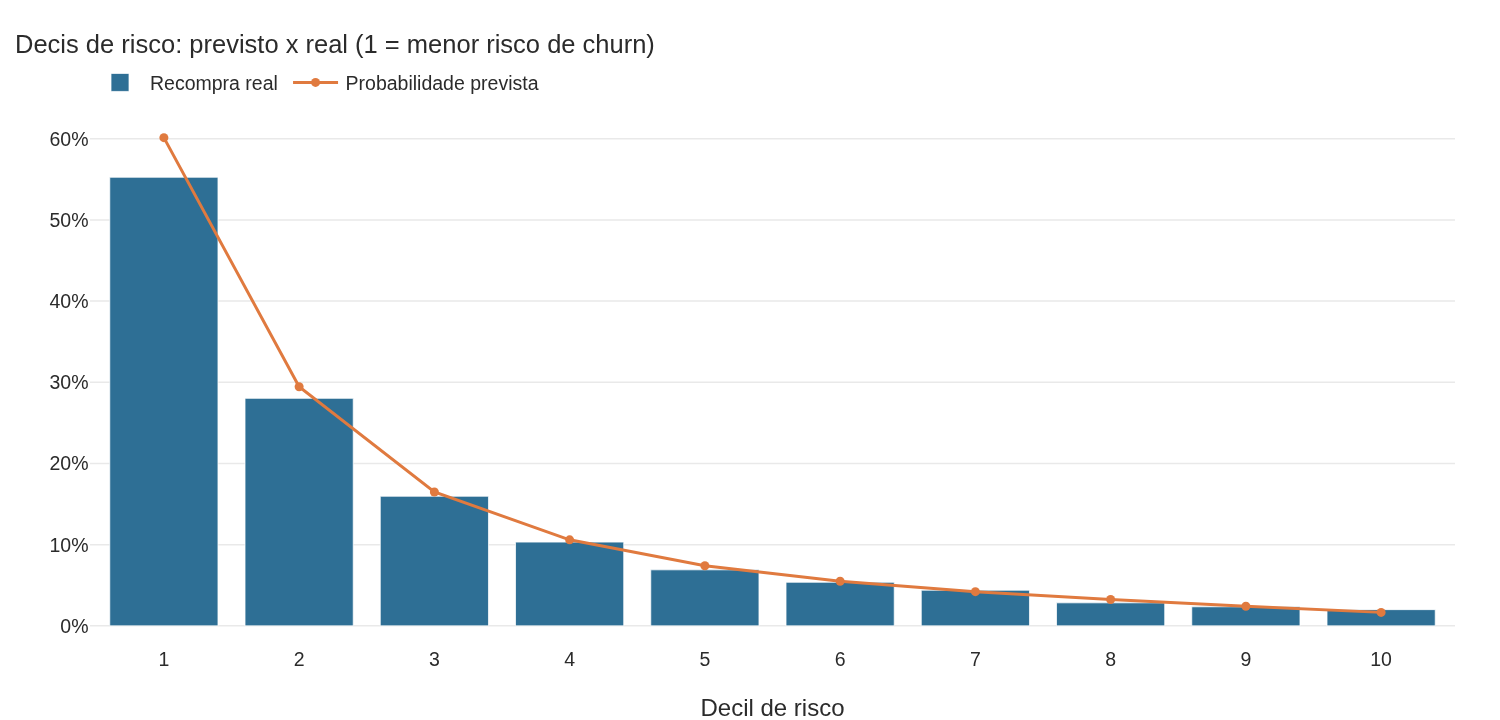

,clientes,prob_media,recompra_real,receita_hist_media
decil_risco,,,,
1,4304,60.1%,55.3%,"R$ 2,165"
2,4304,29.5%,28.0%,"R$ 1,136"
3,4304,16.5%,16.0%,R$ 907
4,4304,10.6%,10.3%,R$ 924
5,4304,7.4%,6.9%,R$ 836
6,4303,5.5%,5.4%,R$ 699
7,4304,4.2%,4.4%,R$ 533
8,4304,3.2%,2.8%,R$ 389
9,4304,2.4%,2.3%,R$ 236


In [7]:
# Calibração e decis de risco de churn (1 - prob. de recompra)
te = pd.DataFrame({"p_recompra": p_lgb, "recomprou": y_te.values, "receita_90d": rec_te.values,
                   "receita_hist": X_te["receita"].values, "pedidos": X_te["pedidos"].values}, index=X_te.index)
te["decil_risco"] = pd.qcut(1 - te.p_recompra, 10, labels=range(1, 11))
dec = te.groupby("decil_risco", observed=True).agg(clientes=("recomprou", "size"), prob_media=("p_recompra", "mean"),
                                                   recompra_real=("recomprou", "mean"), receita_hist_media=("receita_hist", "mean"))
fig = go.Figure()
fig.add_bar(x=dec.index.astype(str), y=dec.recompra_real, name="Recompra real", marker_color=COR_REAL)
fig.add_scatter(x=dec.index.astype(str), y=dec.prob_media, name="Probabilidade prevista", mode="lines+markers", line=dict(color=COR_PREVISTO))
fig.update_layout(title="Decis de risco: previsto x real (1 = menor risco de churn)", xaxis_title="Decil de risco", yaxis_tickformat=".0%")
fig.show()
dec.style.format({"prob_media": "{:.1%}", "recompra_real": "{:.1%}", "receita_hist_media": "R$ {:,.0f}"})

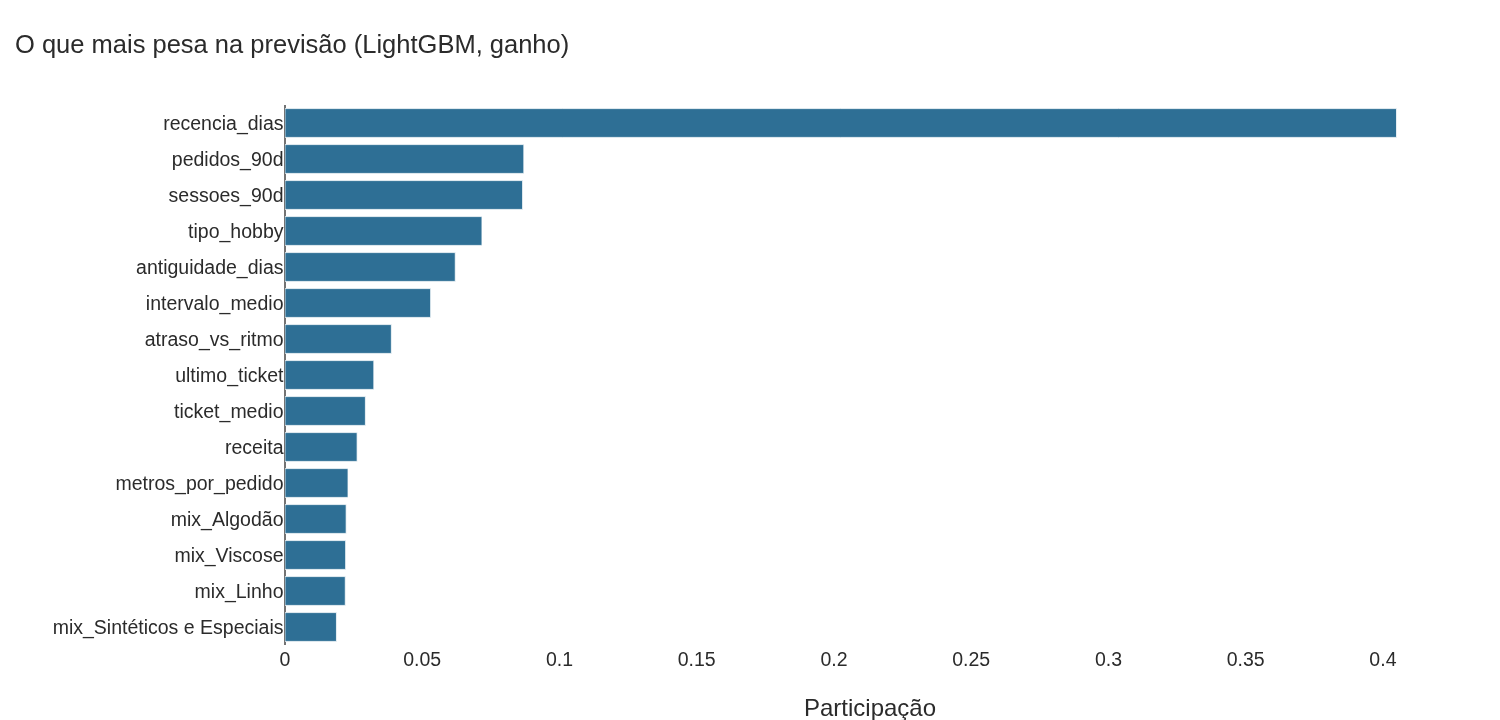

In [8]:
imp = pd.Series(m.feature_importance("gain"), index=feats).sort_values().tail(15)
fig = px.bar(x=imp.values / imp.sum(), y=imp.index, orientation="h", title="O que mais pesa na previsão (LightGBM, ganho)",
             labels={"x": "Participação", "y": ""})
fig.update_layout(margin=dict(l=190))
fig.update_traces(marker_color=COR_REAL)
fig.show()

## Where to act: risk x value

A reactivation campaign costs money (coupon, send, customer service). We prioritize **valuable** customers (historical revenue above the median) with **intermediate to high risk**. Those who will come back on their own do not need a coupon; those lost for years rarely respond.

Simulation assumptions: a 10% coupon and an 8 percentage point increase in the repurchase rate of those who receive it (a typical reactivation effect; to be measured with a control group).

In [9]:
alvo = te[(te.receita_hist >= te.receita_hist.median()) & (te.p_recompra.between(0.15, 0.6))]
ticket_alvo = ped[ped.cliente.isin(alvo.index)].total.mean()
uplift, desconto = 0.08, 0.10
pedidos_extra = len(alvo) * uplift
receita_extra = pedidos_extra * ticket_alvo
custo_cupom = (alvo.p_recompra.sum() + pedidos_extra) * ticket_alvo * desconto  # desconto vai também para quem compraria
print(f"Público-alvo: {len(alvo):,} clientes ({len(alvo) / len(te):.1%} da base ativa) | ticket médio {brl(ticket_alvo)}")
print(f"Pedidos incrementais esperados: {pedidos_extra:,.0f} | receita incremental: {brl(receita_extra)} | custo do desconto: {brl(custo_cupom)}")
print(f"Retorno sobre o desconto: {receita_extra / custo_cupom:.1f}x")
top = dec.iloc[:2].recompra_real.mean(), dec.iloc[-2:].recompra_real.mean()
print(f"Recompra real: {top[0]:.1%} nos 2 decis de menor risco x {top[1]:.1%} nos 2 de maior risco")

Público-alvo: 6,307 clientes (14.7% da base ativa) | ticket médio R$ 352
Pedidos incrementais esperados: 505 | receita incremental: R$ 177.645 | custo do desconto: R$ 90.969
Retorno sobre o desconto: 2.0x
Recompra real: 41.6% nos 2 decis de menor risco x 2.2% nos 2 de maior risco


## Business conclusions

1. **Repurchase is rare and concentrated.** Only 13% of active customers buy again within 90 days. The model separates those who come back well: 55% repurchase in the lowest-risk decile against 2% in the highest-risk one (ROC AUC 0.83).
2. **Logistic regression ties with LightGBM** (AUC 0.828 vs. 0.827, same Brier score). For production, the logistic model is simpler to explain and maintain. The probabilities are well calibrated: predicted tracks actual in every decile.
3. **Recency dominates the prediction** (~40% of LightGBM's gain), followed by orders and website sessions in the last 90 days (~9% each). Having visited the store recently is the best sign of return; the declared customer type (hobby) comes right after.
4. **Where to act:** 6.3k customers (15% of the active base) have historical revenue above the median and intermediate risk. Assuming +8 points of repurchase and a 10% coupon, a reactivation campaign would bring ~505 orders and R$ 178k in revenue for R$ 91k in discounts (2.0x). The 8-point uplift is an assumption: validate it with a control group before scaling.
5. **Do not give coupons to those who will come back anyway.** The two lowest-risk deciles repurchase 42% of the time with no incentive; a discount there only cuts margin.